## Анализ законодательной активности (1992–2025)

In [1]:
# импорты
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from statsmodels.tsa.seasonal import seasonal_decompose
from src.config import DB_PATH, DOCS
from src.queries import run_query

### 1. Данные из базы
Каждая строка — один акт: год, отменён ли, длина названия и сколько у него сфер, форм и органов (считается по таблицам связи). Период 1992–2025 — по итогам аудита.

In [2]:
# акты с признаками из SQL
conn = sqlite3.connect(DB_PATH)
acts = pd.read_sql("""
    SELECT a.act_id, a.date_adopted, a.year, a.is_repealed,
           length(a.title) AS title_len,
           (SELECT COUNT(*) FROM act_areas  aa WHERE aa.act_id = a.act_id) AS n_areas,
           (SELECT COUNT(*) FROM act_forms  af WHERE af.act_id = a.act_id) AS n_forms,
           (SELECT COUNT(*) FROM act_bodies ab WHERE ab.act_id = a.act_id) AS n_bodies
    FROM acts a
    WHERE a.year BETWEEN 1992 AND 2025
""", conn, parse_dates=["date_adopted"])
conn.close()
acts.shape

(214246, 8)

### 2. EDA: описательная статистика и типы признаков

In [3]:
# статистика числовых признаков
acts.drop(columns=["act_id", "date_adopted"]).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,214246.0,2015.90,7.40,1992.0,2012.0,2017.0,2022.0,2025.0
is_repealed,214246.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
title_len,214246.0,167.34,94.63,4.0,99.0,157.0,208.0,4071.0
n_areas,214246.0,1.98,0.84,0.0,1.0,2.0,2.0,12.0
n_forms,214246.0,1.48,0.61,0.0,1.0,1.0,2.0,7.0
n_bodies,214246.0,1.02,0.16,0.0,1.0,1.0,1.0,13.0


In [4]:
# типы признаков
acts.dtypes

act_id                   int64
date_adopted    datetime64[us]
year                     int64
is_repealed              int64
title_len                int64
n_areas                  int64
n_forms                  int64
n_bodies                 int64
dtype: object

**Результат (EDA):**
- Типы признаков: количественные — `title_len`, `n_areas`, `n_forms`, `n_bodies`; бинарный — `is_repealed`; временные — `date_adopted`, `year`; `act_id` — идентификатор.
- Медиана года — 2017: половина актов принята за последние ~9 лет.
- Отменено 35 % актов (среднее `is_repealed` = 0.35).
- Обычно у акта 2 сферы, 1–2 формы и 1 орган; совместные акты нескольких органов редки (std `n_bodies` = 0.16).
- `title_len`: медиана 157 символов, но максимум 4 071 — длинный хвост очень длинных названий.

### 3. Временной ряд и выбросы (IQR)

In [5]:
# актов в каждом месяце
monthly = acts.set_index("date_adopted").resample("MS").size()

In [6]:
# выбросы по правилу IQR
q1, q3 = monthly.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = monthly[(monthly < q1 - 1.5 * iqr) | (monthly > q3 + 1.5 * iqr)]
print("выбросов (месяцев):", len(outliers))
outliers

выбросов (месяцев): 7


date_adopted
2015-12-01    2007
2020-12-01    2515
2021-12-01    2716
2022-12-01    2932
2023-12-01    2995
2024-12-01    2816
2025-12-01    2392
dtype: int64

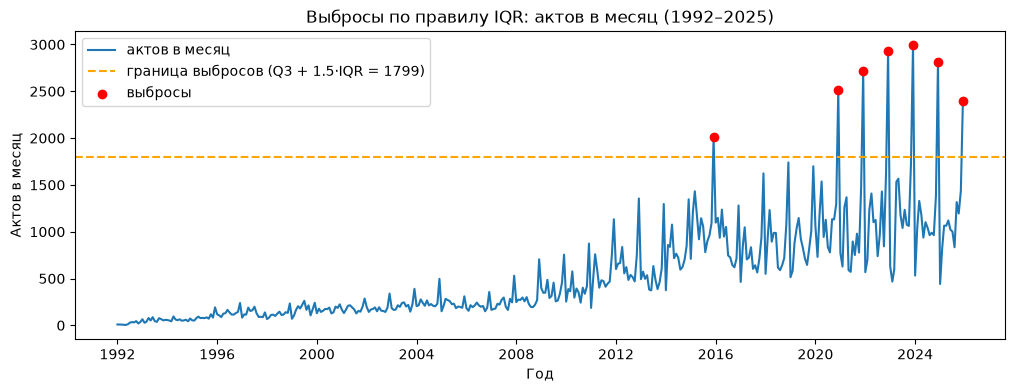

In [7]:
# выбросы на графике ряда
upper = q3 + 1.5 * iqr
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, label="актов в месяц")
ax.axhline(upper, color="orange", linestyle="--", label=f"граница выбросов (Q3 + 1.5·IQR = {upper:.0f})")
ax.scatter(outliers.index, outliers.values, color="red", zorder=3, label="выбросы")
ax.set_title("Выбросы по правилу IQR: актов в месяц (1992–2025)")
ax.set_xlabel("Год")
ax.set_ylabel("Актов в месяц")
ax.legend()
plt.show()

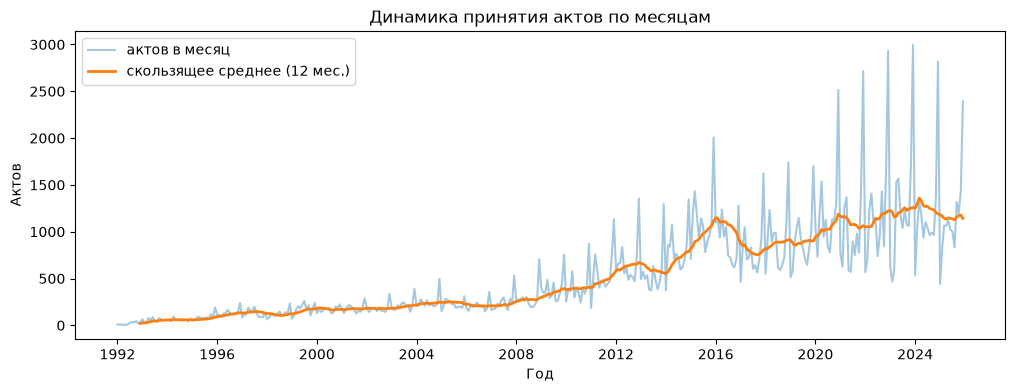

In [8]:
# ряд и скользящее среднее
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, alpha=0.4, label="актов в месяц")
ax.plot(monthly.index, monthly.rolling(12).mean(), linewidth=2, label="скользящее среднее (12 мес.)")
ax.set_title("Динамика принятия актов по месяцам")
ax.set_xlabel("Год")
ax.set_ylabel("Актов")
ax.legend()
plt.show()

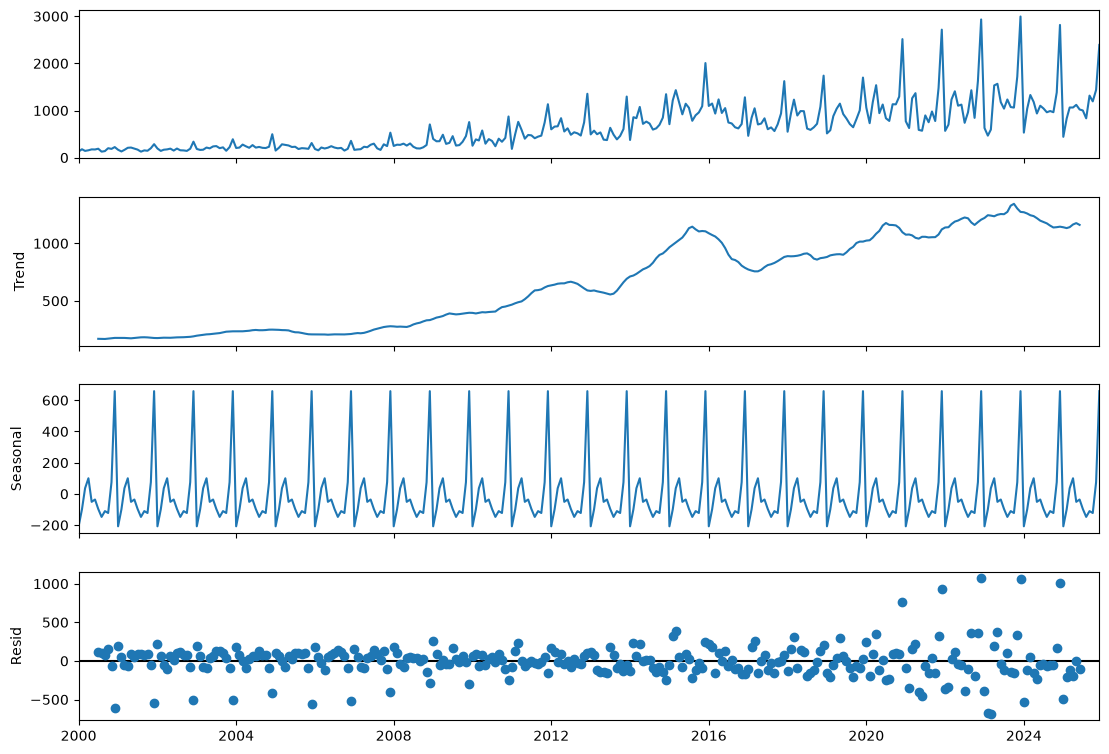

date_adopted
1    -208.0
2     -99.0
3      37.0
4     100.0
5     -51.0
6     -36.0
7     -97.0
8    -147.0
9    -110.0
10   -122.0
11     75.0
12    658.0
Name: seasonal, dtype: float64

In [9]:
# сезонная декомпозиция с 2000
decomp = seasonal_decompose(monthly.loc["2000":], model="additive", period=12)
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.show()

# средний сезонный эффект
decomp.seasonal.groupby(decomp.seasonal.index.month).mean().round(0)

**Результат (временной ряд):**
- Активность росла с 1992 года (241 акт) до пика в 2023 (15 092); в 2022–2025 стабильно 13.7–15 тыс. актов в год.
- Выбросов по IQR — 7 месяцев, и все они декабри (2015, 2020–2025, до 2 995 актов). Это не ошибки данных, а реальная сезонность.
- Декомпозиция подтверждает: в декабре в среднем на ~650 актов больше обычного, в январе на ~200 меньше. Конец года — принятие бюджетов, планов и отчётов.
- Скользящее среднее за 12 месяцев убирает сезонность и показывает общий рост.

### 4. Корреляции

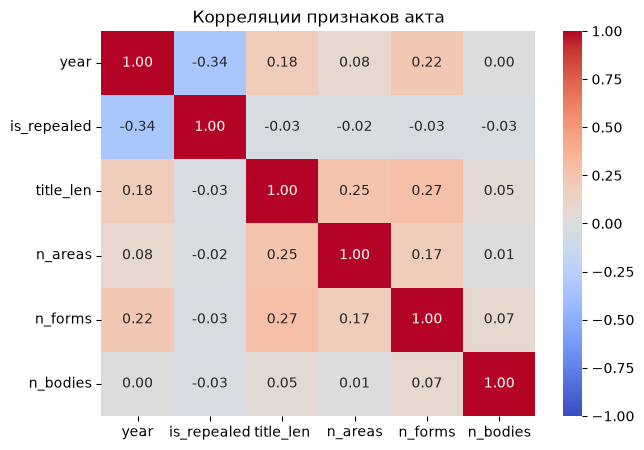

In [10]:
# корреляции признаков (heatmap)
cols = ["year", "is_repealed", "title_len", "n_areas", "n_forms", "n_bodies"]
corr = acts[cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Корреляции признаков акта")
plt.show()

**Результат (корреляции):**
- Все связи слабые (|r| < 0.35), сильно зависимых признаков нет.
- Самая заметная — `year` ↔ `is_repealed` (−0.34): чем старше акт, тем чаще он отменён — у него было больше времени, чтобы его заменили.
- `title_len` слабо связан с `n_areas` и `n_forms` (~0.25): акты с длинными названиями чаще охватывают несколько сфер и форм (например, «о внесении изменений…»).

### 5. Результаты SQL-запросов

In [11]:
# интерактивный график по годам
yearly = run_query("acts_per_year")
fig = px.bar(
    yearly, x="year", y="acts", color="repealed_pct",
    hover_data=["repealed", "repealed_pct"],
    labels={"year": "Год", "acts": "Актов", "repealed_pct": "Отменено, %", "repealed": "Отменено"},
    title="Актов по годам и доля отменённых",
)
fig.show()

# сохраняем в HTML
fig.write_html(DOCS / "acts_per_year.html")

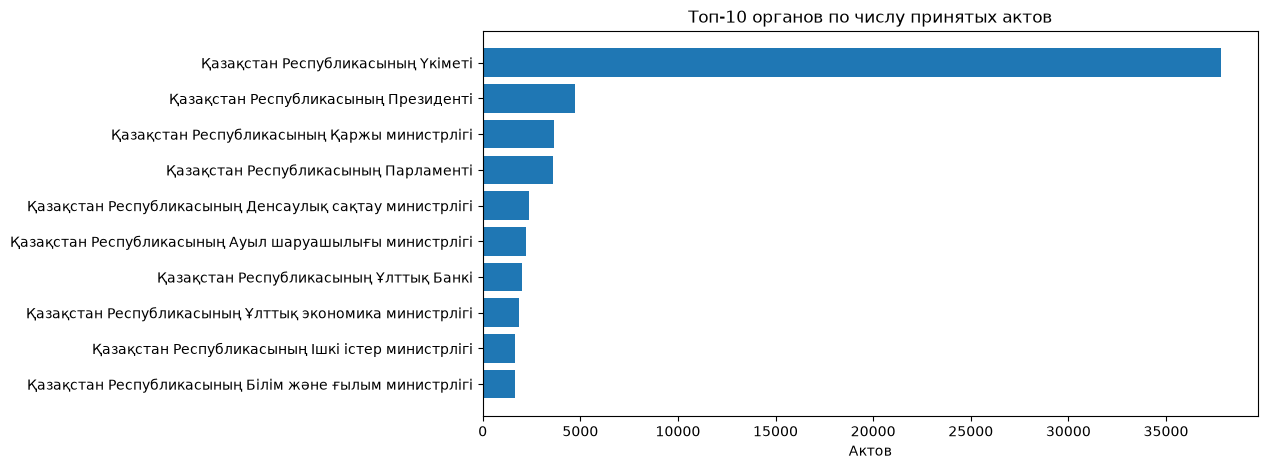

In [12]:
# топ-10 органов
top = run_query("top_bodies")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["body"][::-1], top["acts"][::-1])
ax.set_title("Топ-10 органов по числу принятых актов")
ax.set_xlabel("Актов")
plt.show()

**Результат (SQL):**
- Доля отменённых: 40–65 % у актов 1992–2015 годов (максимум ~59 % в 2015), затем резко падает — 25 % в 2020, 7 % в 2023, 0.6 % в 2025. Свежие акты ещё просто не успели отменить.
- Больше всего актов принимает Правительство (37 809) — почти в 8 раз больше, чем Президент (4 728), следующий в списке.

## Итоги анализа
1. **Динамика:** законодательная активность выросла с 241 акта в 1992 году до ~14–15 тыс. в год в 2022–2025, пик — 2023 год.
2. **Сезонность:** ярко выражена — каждый декабрь резкий всплеск (до 3 тыс. актов в месяц), в январе спад. Все выбросы по IQR — декабри.
3. **Отмена:** отменено 35 % актов; у актов до 2015 года — около половины, у свежих — единицы процентов.
4. **Органы:** главный «законодатель» — Правительство, с большим отрывом от остальных.
5. **Структура акта:** обычно 1 орган, 1–2 формы, 2 сферы регулирования; сильных зависимостей между признаками нет.
6. **Для прогноза:** ряд имеет тренд и 12-месячную сезонность — поэтому baseline-ом берём seasonal naive.